In [ ]:
!pip install pandas numpy matplotlib seaborn scikit-learn

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

DATA_DIR = Path("data/raw")
OUTPUT_DIR = Path("data/cleaned")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Load the main sales data
sales = pd.read_csv(DATA_DIR / "train.csv")
stores = pd.read_csv(DATA_DIR / "stores.csv")
holidays = pd.read_csv(DATA_DIR / "holidays_events.csv")
transactions = pd.read_csv(DATA_DIR / "transactions.csv")

print("Sales shape:", sales.shape)
print("Stores shape:", stores.shape)
print("Holidays shape:", holidays.shape)
print("Transactions shape:", transactions.shape)

print("\nSales columns:")
print(sales.columns.tolist())

sales.head()

Sales shape: (3000888, 6)
Stores shape: (54, 5)
Holidays shape: (350, 6)
Transactions shape: (83488, 3)

Sales columns:
['id', 'date', 'store_nbr', 'family', 'sales', 'onpromotion']


,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,1,2013-01-01,1,BABY CARE,0.0,0
2,2,2013-01-01,1,BEAUTY,0.0,0
3,3,2013-01-01,1,BEVERAGES,0.0,0
4,4,2013-01-01,1,BOOKS,0.0,0


In [7]:
# Inspect the data
sales.info()
print(sales.describe(include="all").T)

# Missing values
print("\nMissing values:")
print(sales.isnull().sum())

# Duplicate records
print("\nExact duplicate rows:", sales.duplicated().sum())

# Check important columns
print("\nUnique product families:",
      sales["family"].nunique())

print("Unique stores:",
      sales["store_nbr"].nunique())

print("Date range:",
      sales["date"].min(), "to", sales["date"].max())

# Check unusual values
print("Negative sales:", (sales["sales"] < 0).sum())
print("Zero sales:", (sales["sales"] == 0).sum())
print("Negative promotion counts:",
      (pd.to_numeric(sales["onpromotion"], errors="coerce") < 0).sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000888 entries, 0 to 3000887
Data columns (total 6 columns):
 #   Column       Dtype  
---  ------       -----  
 0   id           int64  
 1   date         object 
 2   store_nbr    int64  
 3   family       object 
 4   sales        float64
 5   onpromotion  int64  
dtypes: float64(1), int64(3), object(2)
memory usage: 137.4+ MB
                 count unique         top   freq        mean            std  \
id           3000888.0    NaN         NaN    NaN   1500443.5  866281.891642   
date           3000888   1684  2017-08-15   1782         NaN            NaN   
store_nbr    3000888.0    NaN         NaN    NaN        27.5      15.585787   
family         3000888     33  AUTOMOTIVE  90936         NaN            NaN   
sales        3000888.0    NaN         NaN    NaN  357.775749    1101.997721   
onpromotion  3000888.0    NaN         NaN    NaN     2.60277      12.218882   

             min        25%        50%         75%        max 

In [8]:
# Remove exact duplicate records
sales = sales.drop_duplicates().copy()

# Standardize dates and numeric fields
sales["date"] = pd.to_datetime(sales["date"], errors="coerce")
sales["sales"] = pd.to_numeric(sales["sales"], errors="coerce")
sales["onpromotion"] = pd.to_numeric(
    sales["onpromotion"], errors="coerce"
)

# Remove rows without essential sales information
sales = sales.dropna(
    subset=["date", "store_nbr", "family", "sales"]
).copy()

# Standardize category names
sales["family"] = (
    sales["family"].astype(str).str.strip().str.upper()
)

# Treat missing promotion counts as no recorded promotion
sales["onpromotion"] = sales["onpromotion"].fillna(0)

# Normalize store metadata
stores.columns = stores.columns.str.strip()
stores = stores.drop_duplicates(subset=["store_nbr"])

# Normalize transaction data
transactions["date"] = pd.to_datetime(
    transactions["date"], errors="coerce"
)
transactions = transactions.dropna(
    subset=["date", "store_nbr"]
)
transactions = transactions.drop_duplicates(
    subset=["date", "store_nbr"]
)

# Prepare holiday/event data
holidays["date"] = pd.to_datetime(
    holidays["date"], errors="coerce"
)
holidays = holidays.dropna(subset=["date"]).copy()

# Create one calendar record per date
holidays["event_description"] = (
    holidays["description"].fillna("").astype(str).str.strip()
)

calendar = holidays.groupby("date").agg(
    holiday=("type", lambda x: int(
        x.astype(str).str.lower().isin(
            ["holiday", "additional", "bridge", "transfer"]
        ).any()
    )),
    event_description=(
        "event_description",
        lambda x: " | ".join(sorted(set(v for v in x if v)))
    )
).reset_index()

calendar["festival"] = calendar["event_description"].apply(
    lambda x: int(bool(x.strip()))
)

# Combine sales with store details
df = sales.merge(
    stores, on="store_nbr", how="left",
    validate="many_to_one"
)

# Add transaction counts
df = df.merge(
    transactions[["date", "store_nbr", "transactions"]],
    on=["date", "store_nbr"],
    how="left",
    validate="many_to_one"
)

# Add calendar details
df = df.merge(
    calendar, on="date", how="left",
    validate="many_to_one"
)

df["holiday"] = df["holiday"].fillna(0).astype(int)
df["festival"] = df["festival"].fillna(0).astype(int)
df["event_description"] = df["event_description"].fillna("")

print("Combined dataset shape:", df.shape)
print(df.head())

Combined dataset shape: (3000888, 14)
   id       date  store_nbr      family  sales  onpromotion   city      state  \
0   0 2013-01-01          1  AUTOMOTIVE    0.0            0  Quito  Pichincha   
1   1 2013-01-01          1   BABY CARE    0.0            0  Quito  Pichincha   
2   2 2013-01-01          1      BEAUTY    0.0            0  Quito  Pichincha   
3   3 2013-01-01          1   BEVERAGES    0.0            0  Quito  Pichincha   
4   4 2013-01-01          1       BOOKS    0.0            0  Quito  Pichincha   

  type  cluster  transactions  holiday   event_description  festival  
0    D       13           NaN        1  Primer dia del ano         1  
1    D       13           NaN        1  Primer dia del ano         1  
2    D       13           NaN        1  Primer dia del ano         1  
3    D       13           NaN        1  Primer dia del ano         1  
4    D       13           NaN        1  Primer dia del ano         1  


In [9]:
# Time-based features
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["month_name"] = df["date"].dt.month_name()
df["day"] = df["date"].dt.day
df["weekday"] = df["date"].dt.day_name()
df["week"] = df["date"].dt.isocalendar().week.astype(int)

# Quarter as a seasonal proxy
df["quarter"] = "Q" + df["date"].dt.quarter.astype(str)

# Promotion indicator
df["promotion_flag"] = (df["onpromotion"] > 0).astype(int)

# Sales per recorded transaction; not average basket value
df["sales_per_transaction"] = np.where(
    df["transactions"].fillna(0) > 0,
    df["sales"] / df["transactions"],
    np.nan
)

# Flag records that need further investigation
df["negative_sales_flag"] = (df["sales"] < 0).astype(int)

print(df[[
    "date", "family", "sales", "onpromotion",
    "promotion_flag", "weekday", "quarter", "holiday"
]].head())

        date      family  sales  onpromotion  promotion_flag  weekday quarter  \
0 2013-01-01  AUTOMOTIVE    0.0            0               0  Tuesday      Q1   
1 2013-01-01   BABY CARE    0.0            0               0  Tuesday      Q1   
2 2013-01-01      BEAUTY    0.0            0               0  Tuesday      Q1   
3 2013-01-01   BEVERAGES    0.0            0               0  Tuesday      Q1   
4 2013-01-01       BOOKS    0.0            0               0  Tuesday      Q1   

   holiday  
0        1  
1        1  
2        1  
3        1  
4        1  


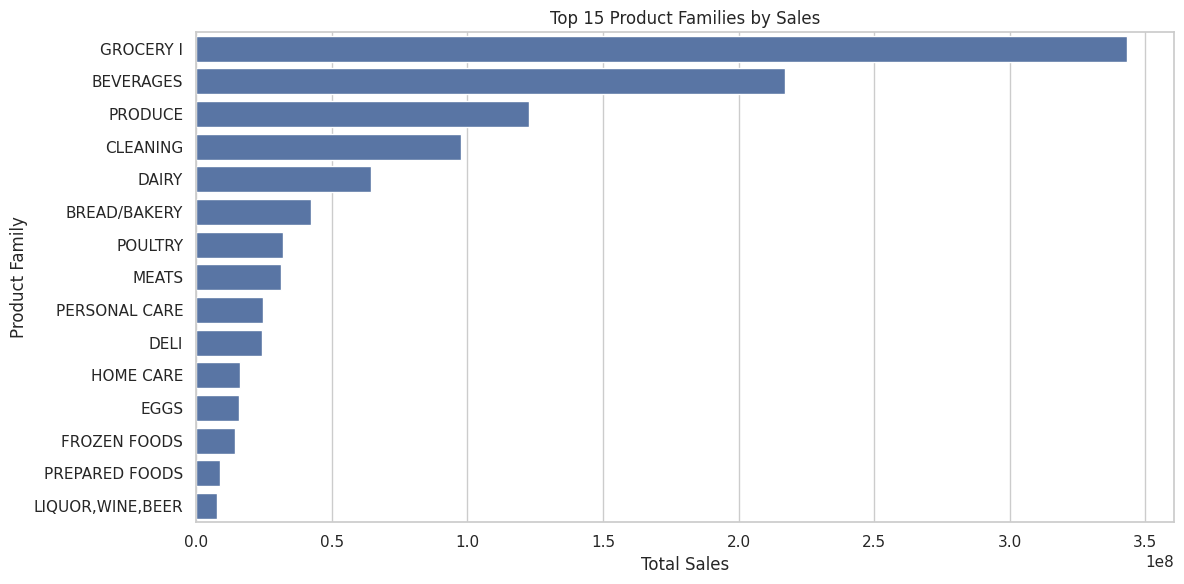

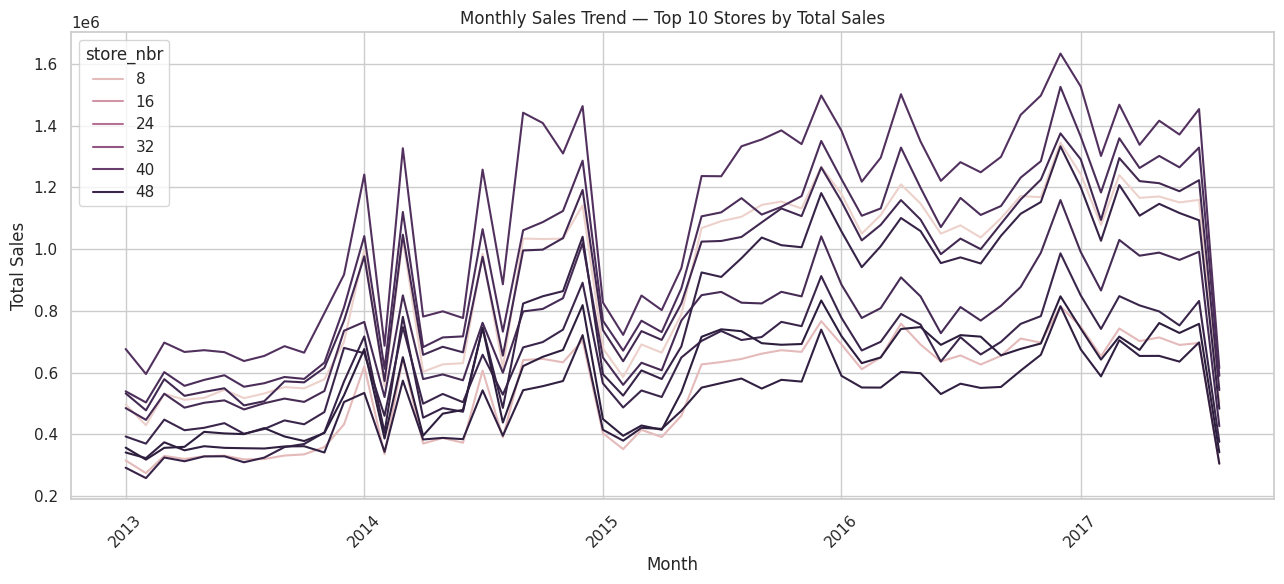

   promotion_flag  average_sales   total_sales  records
0               0     158.246681  3.781398e+08  2389559
1               1    1137.693730  6.955052e+08   611329


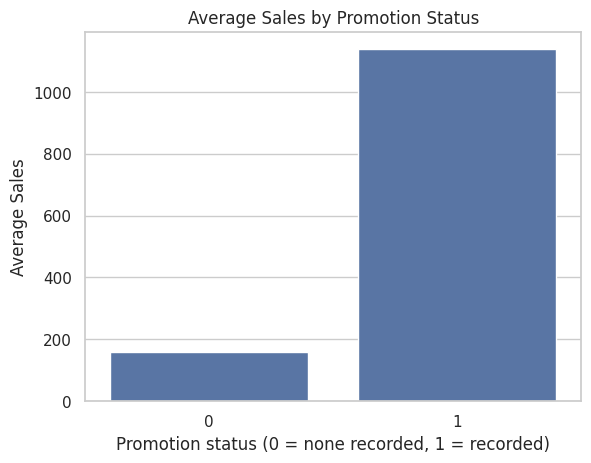

   festival  average_sales   total_sales  records
0         0     352.159181  8.986482e+08  2551824
1         1     389.692123  1.749967e+08   449064


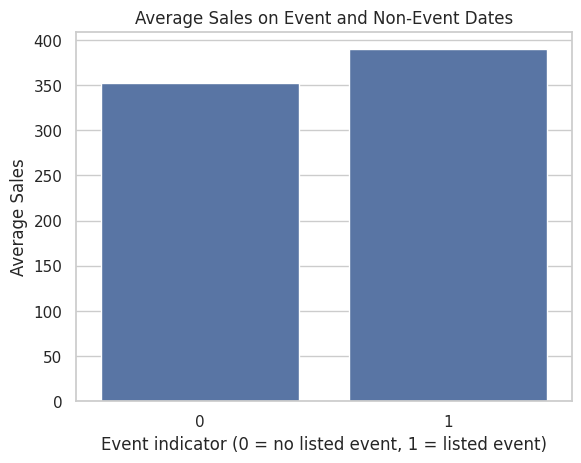

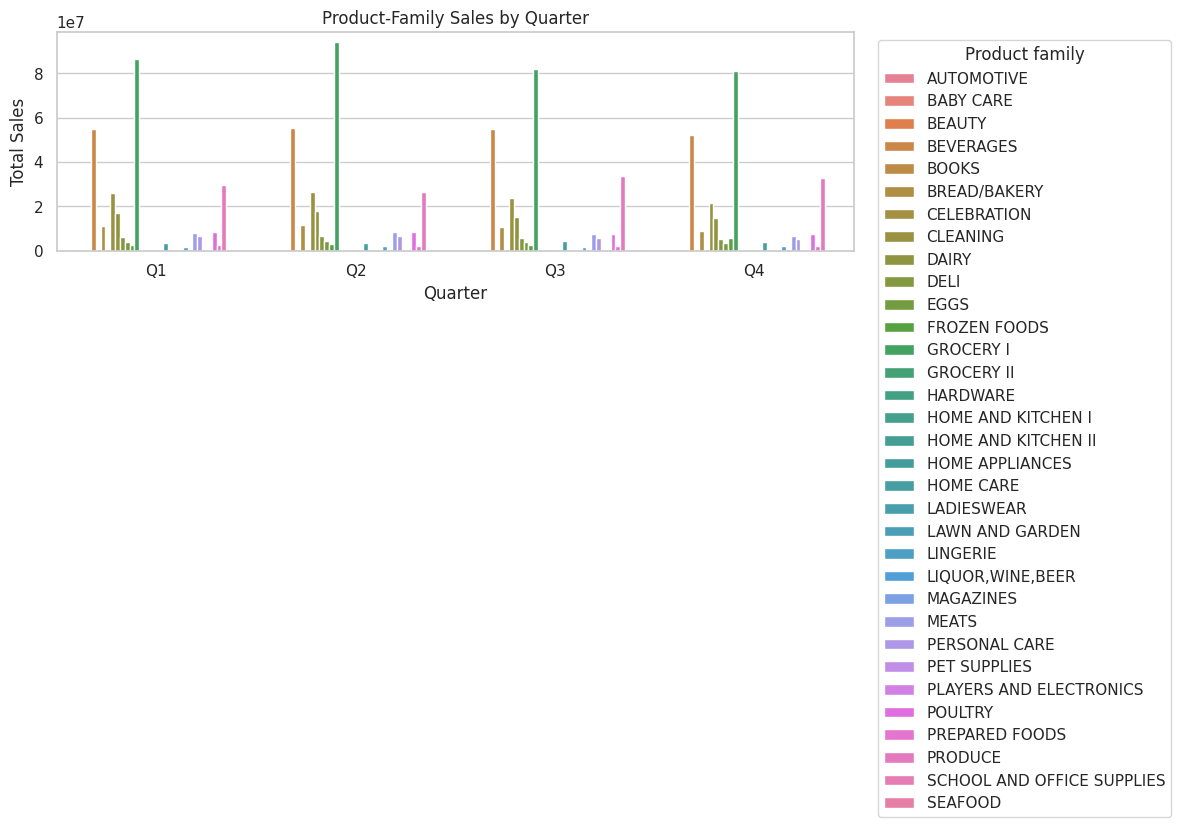

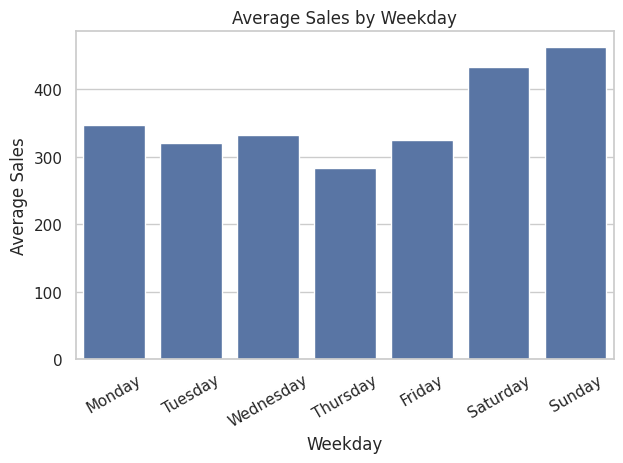

In [10]:
sns.set_theme(style="whitegrid")

# 1. Which product categories drive revenue?
category_revenue = (
    df.groupby("family", as_index=False)["sales"]
      .sum()
      .sort_values("sales", ascending=False)
)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=category_revenue.head(15),
    x="sales", y="family"
)
plt.title("Top 15 Product Families by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Product Family")
plt.tight_layout()
plt.show()


# 2. Which stores grow fastest?
monthly_store = (
    df.assign(month_start=df["date"].dt.to_period("M").dt.to_timestamp())
      .groupby(["month_start", "store_nbr"], as_index=False)["sales"]
      .sum()
)

top_stores = (
    monthly_store.groupby("store_nbr")["sales"]
    .sum().nlargest(10).index
)

plt.figure(figsize=(13, 6))
sns.lineplot(
    data=monthly_store[
        monthly_store["store_nbr"].isin(top_stores)
    ],
    x="month_start", y="sales",
    hue="store_nbr", estimator=None
)
plt.title("Monthly Sales Trend — Top 10 Stores by Total Sales")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# 3. Promotion versus non-promotion
promotion_comparison = (
    df.groupby("promotion_flag", as_index=False)
      .agg(
          average_sales=("sales", "mean"),
          total_sales=("sales", "sum"),
          records=("sales", "size")
      )
)

print(promotion_comparison)

sns.barplot(
    data=promotion_comparison,
    x="promotion_flag", y="average_sales"
)
plt.title("Average Sales by Promotion Status")
plt.xlabel("Promotion status (0 = none recorded, 1 = recorded)")
plt.ylabel("Average Sales")
plt.show()


# 4. Festival/event versus other dates
festival_comparison = (
    df.groupby("festival", as_index=False)
      .agg(
          average_sales=("sales", "mean"),
          total_sales=("sales", "sum"),
          records=("sales", "size")
      )
)

print(festival_comparison)

sns.barplot(
    data=festival_comparison,
    x="festival", y="average_sales"
)
plt.title("Average Sales on Event and Non-Event Dates")
plt.xlabel("Event indicator (0 = no listed event, 1 = listed event)")
plt.ylabel("Average Sales")
plt.show()


# 5. Quarterly/seasonal demand
quarter_sales = (
    df.groupby(["quarter", "family"], as_index=False)["sales"]
      .sum()
)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=quarter_sales,
    x="quarter", y="sales", hue="family",
    errorbar=None
)
plt.title("Product-Family Sales by Quarter")
plt.xlabel("Quarter")
plt.ylabel("Total Sales")
plt.legend(
    title="Product family",
    bbox_to_anchor=(1.02, 1), loc="upper left"
)
plt.tight_layout()
plt.show()


# 6. Peak shopping periods
weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

weekday_sales = (
    df.groupby("weekday", as_index=False)["sales"]
      .mean()
)
weekday_sales["weekday"] = pd.Categorical(
    weekday_sales["weekday"],
    categories=weekday_order,
    ordered=True
)
weekday_sales = weekday_sales.sort_values("weekday")

sns.barplot(
    data=weekday_sales,
    x="weekday", y="sales"
)
plt.title("Average Sales by Weekday")
plt.xlabel("Weekday")
plt.ylabel("Average Sales")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [11]:
from sklearn.feature_selection import SelectKBest, f_regression

# Take a sample to keep feature selection efficient
model_data = df[
    ["sales", "store_nbr", "family", "weekday",
     "quarter", "promotion_flag", "holiday", "festival"]
].dropna().sample(
    n=min(50000, len(df)), random_state=42
)

X = pd.get_dummies(
    model_data.drop(columns="sales"),
    columns=["family", "weekday", "quarter"],
    drop_first=True,
    dtype=int
)
y = model_data["sales"]

selector = SelectKBest(score_func=f_regression, k=min(10, X.shape[1]))
selector.fit(X, y)

selected_features = pd.DataFrame({
    "feature": X.columns,
    "score": selector.scores_
}).sort_values("score", ascending=False)

print("Top selected features:")
print(selected_features.head(10))

selected_features.to_csv(
    OUTPUT_DIR / "selected_features.csv", index=False
)

Top selected features:
                   feature         score
15        family_GROCERY I  21918.882151
1           promotion_flag   7360.704429
6         family_BEVERAGES   5371.985873
33          family_PRODUCE   1165.435907
10         family_CLEANING    702.489207
7             family_BOOKS    171.949981
11            family_DAIRY    168.952206
29     family_PET SUPPLIES    167.710303
20  family_HOME APPLIANCES    163.042807
26        family_MAGAZINES    162.539554


In [12]:
# Add month start for monthly summaries
df["month_start"] = df["date"].dt.to_period("M").dt.to_timestamp()

# Full cleaned dataset for Python analysis
df.to_csv(
    OUTPUT_DIR / "cleaned_sales.csv", index=False
)

# Monthly sales by store and product family
monthly_summary = (
    df.groupby(
        ["month_start", "store_nbr", "family"],
        as_index=False
    )
    .agg(
        total_sales=("sales", "sum"),
        total_promotion_count=("onpromotion", "sum"),
        promotion_record_share=("promotion_flag", "mean"),
        event_record_share=("festival", "mean"),
        holiday_record_share=("holiday", "mean"),
        record_count=("sales", "size")
    )
)

# Add store details for analysis
monthly_summary = monthly_summary.merge(
    stores, on="store_nbr", how="left",
    validate="many_to_one"
)

monthly_summary.to_csv(
    OUTPUT_DIR / "excel_ready_monthly.csv", index=False
)

# Daily sales by store for peak-period and store-trend analysis
daily_store = (
    df.groupby(["date", "store_nbr"], as_index=False)
      .agg(
          total_sales=("sales", "sum"),
          transactions=("transactions", "max"),
          promotion_count=("onpromotion", "sum"),
          festival=("festival", "max"),
          holiday=("holiday", "max")
      )
)

daily_store.to_csv(
    OUTPUT_DIR / "daily_store_sales.csv", index=False
)

# Category-level summary
category_summary = (
    df.groupby("family", as_index=False)
      .agg(
          total_sales=("sales", "sum"),
          average_sales=("sales", "mean"),
          total_promotion_count=("onpromotion", "sum"),
          record_count=("sales", "size")
      )
      .sort_values("total_sales", ascending=False)
)

category_summary.to_csv(
    OUTPUT_DIR / "category_summary.csv", index=False
)

# Promotion comparison
promotion_summary = (
    df.groupby("promotion_flag", as_index=False)
      .agg(
          average_sales=("sales", "mean"),
          total_sales=("sales", "sum"),
          record_count=("sales", "size")
      )
)

promotion_summary.to_csv(
    OUTPUT_DIR / "promotion_comparison.csv", index=False
)

# Event/festival comparison
festival_summary = (
    df.groupby("festival", as_index=False)
      .agg(
          average_sales=("sales", "mean"),
          total_sales=("sales", "sum"),
          record_count=("sales", "size")
      )
)

festival_summary.to_csv(
    OUTPUT_DIR / "festival_comparison.csv", index=False
)

# Calendar-level peak-period analysis
weekday_summary = (
    df.groupby("weekday", as_index=False)
      .agg(
          average_sales=("sales", "mean"),
          total_sales=("sales", "sum")
      )
)

weekday_summary.to_csv(
    OUTPUT_DIR / "weekday_summary.csv", index=False
)

print("Export complete. Files saved in:", OUTPUT_DIR)
print("Monthly Excel-ready rows:", len(monthly_summary))
print("Daily store summary rows:", len(daily_store))
print("Monthly summary fits Excel:",
      len(monthly_summary) <= 1048576)

Export complete. Files saved in: data/cleaned
Monthly Excel-ready rows: 99792
Daily store summary rows: 90936
Monthly summary fits Excel: True
